# 1. Definition of Z-Score

The **Z-score** (or standard score) is a statistical measurement that describes a data point's relationship to the mean of a group of values, measured in terms of standard deviations. 

In simple terms, it tells you **how many standard deviations away from the mean a specific data point is.**

**The Formula:**

$$Z = \frac{(X - \mu)}{\sigma}$$

Where:
* **$Z$** = The Z-score
* **$X$** = The individual data point
* **$\mu$** = The mean (average) of the dataset
* **$\sigma$** = The standard deviation of the dataset

---

# 2. How Z-Score Identifies Outliers

When detecting outliers, we rely on the **Empirical Rule** (also known as the 68-95-99.7 rule) for normally distributed data:

* ~68% of data falls within 1 standard deviation of the mean (**$Z$** between -1 and 1).
* ~95% of data falls within 2 standard deviations (**$Z$** between -2 and 2).
* ~99.7% of data falls within 3 standard deviations (**$Z$** between -3 and 3).

### The Outlier Threshold:
Because 99.7% of data in a normal distribution falls within 3 standard deviations, any data point with a Z-score greater than 3 or less than -3 (i.e., **$|Z| > 3$**) is highly unusual. Therefore, it is flagged as an outlier. 

*(Note: Depending on the strictness of your analysis, some data scientists use a threshold of 2.5 or 2, but 3 is the industry standard).*

### Pros and Cons of the Z-Score Method

* **Pros:** Extremely easy to calculate and implement; works exceptionally well for large datasets that follow a normal (Gaussian) distribution.
* **Cons:** It assumes the data is normally distributed. Furthermore, because the mean ($\mu$) and standard deviation ($\sigma$) are heavily influenced by extreme values, the outliers themselves can skew the Z-score calculation, making it harder to detect them (this is called the "masking effect"). If your data is highly skewed, the IQR (Interquartile Range) method or Modified Z-score (using the median and MAD) is preferred.

# Outlier Detection using Z-Score
In this notebook, we will:
1. Generate a synthetic dataset with injected outliers.
2. Calculate the Z-scores for our data.
3. Filter and remove the outliers based on a threshold of 3.
4. Visualize the data before and after cleaning.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Set visualization style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

### Step 1: Create Sample Data
We will generate 200 data points from a normal distribution (mean=50, std=10) and manually inject 5 extreme outliers to test our method.

In [6]:
# Set seed for reproducibility
np.random.seed(42)

# Generate normal data
normal_data = np.random.normal(loc=50, scale=10, size=200)

# Inject extreme outliers
injected_outliers = [5, 8, 95, 102, 110]
raw_data = np.append(normal_data, injected_outliers)

# Create a Pandas DataFrame
df = pd.DataFrame(raw_data, columns=['Value'])

print(f"Total data points: {len(df)}")
print(f"Data range: {df['Value'].min()} to {df['Value'].max()}")

Total data points: 205
Data range: 5.0 to 110.0


### Step 2: Calculate Z-Scores
We will use `scipy.stats.zscore` to calculate the Z-score for every row. 
Because we only care about the *magnitude* of the deviation (whether it's too high or too low), we will take the absolute value of the Z-score.

In [7]:
# Calculate Z-scores
df['Z_Score'] = stats.zscore(df['Value'])

# Calculate Absolute Z-Score for easier thresholding
df['Abs_Z_Score'] = np.abs(df['Z_Score'])

# Define threshold
threshold = 3.0

# Identify outliers
df['Is_Outlier'] = df['Abs_Z_Score'] > threshold

# Create a cleaned dataframe
df_clean = df[~df['Is_Outlier']].copy()

print(f"Number of outliers detected: {df['Is_Outlier'].sum()}")
print("\nOutlier Details:")
display(df[df['Is_Outlier']][['Value', 'Z_Score']])

Number of outliers detected: 5

Outlier Details:


,Value,Z_Score
200,5.0,-3.752990
201,8.0,-3.502477
202,95.0,3.762392
203,102.0,4.346922
204,110.0,5.014956


### Step 3: Visualize the Results
We will use boxplots to visualize the spread of the data. The boxplot on the left shows the raw data (with outliers pulling the whiskers), and the right shows the cleaned data.

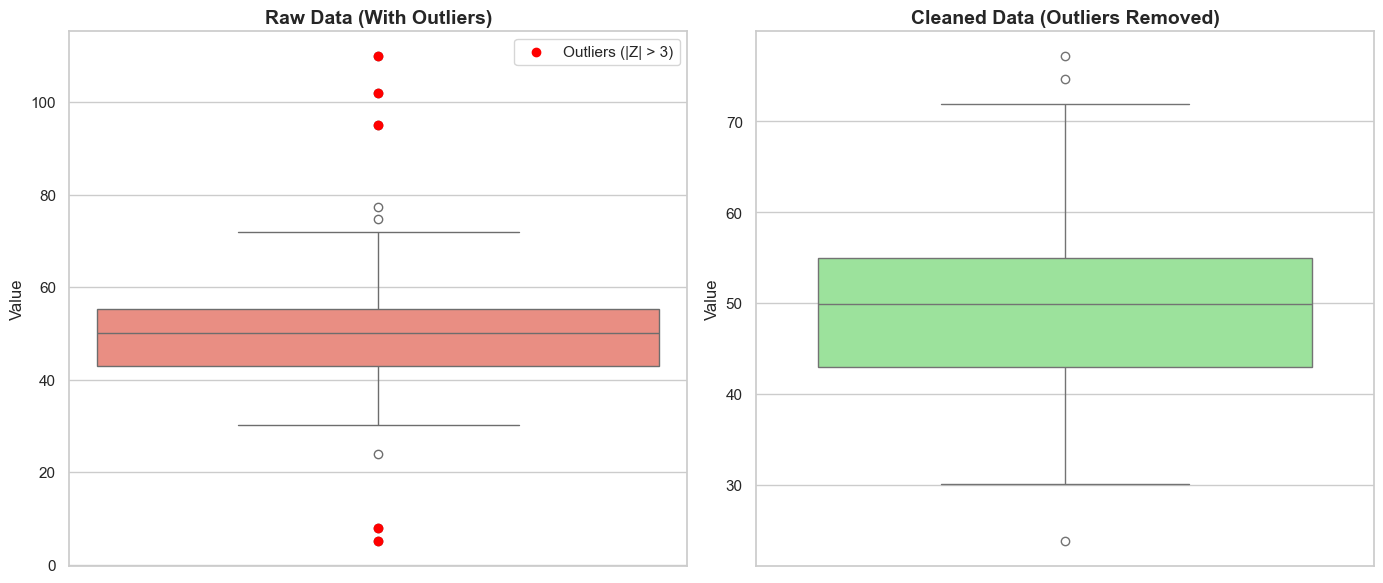

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot 1: Raw Data
sns.boxplot(y=df['Value'], ax=axes[0], color='salmon')
axes[0].set_title('Raw Data (With Outliers)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Value')

# Plot 2: Cleaned Data
sns.boxplot(y=df_clean['Value'], ax=axes[1], color='lightgreen')
axes[1].set_title('Cleaned Data (Outliers Removed)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Value')

# Add a scatter plot overlay to show the exact outlier points on the raw data
outlier_points = df[df['Is_Outlier']]['Value']
axes[0].scatter(x=[0]*len(outlier_points), y=outlier_points, color='red', zorder=5, label='Outliers (|Z| > 3)')
axes[0].legend()

plt.tight_layout()
plt.show()